In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '5,6,7' #0,

import geopandas as gpd
import numpy as np
import os
#os.environ["CUDA_VISIBLE_DEVICES"] = "1,7"

import torch
torch.cuda.device_count()

# geo2llm_demo.py
import math
import random
from typing import List, Dict
from tqdm import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
# from transformers import AdamW
from torch.optim import AdamW

import re
import matplotlib.pyplot as plt
from accelerate import Accelerator


/home/chenchu/.conda/envs/shot/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class Geo2VecEncoder(nn.Module):
    """
    Example encoder: MLP -> reshape to (L_geo, dim)
    """
    def __init__(self, input_dim: int, hidden=256,  out_dim=256):
        super().__init__()
        self.out_dim = out_dim
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)
        )

    def forward(self, x: torch.Tensor):
        # x: (B, input_dim)
        out = self.mlp(x)  # (B,out_dim)
        return out
    
    @property
    def device(self):
        return next(self.parameters()).device

class Geo2LLM_llama(nn.Module):
    """
    Wraps a pretrained LLaMA LM and injects Geo tokens as inputs_embeds.
    """
    def __init__(self, llm,tokenizer,
                 geo_input_dim=256, geo_out_dim=256, geo_device="cuda:0"):
        super().__init__()

        # ---- Load LLaMA ----
        self.llm = llm
        self.tokenizer = tokenizer
        self.llm_hidden = self.llm.config.hidden_size

        self.llm_device = self.llm.device

        # ---- Geo encoders ----
        self.geo_encoder = Geo2VecEncoder(input_dim=geo_input_dim, out_dim=geo_out_dim).to(geo_device)
        self.geo_projector = nn.Linear(geo_out_dim, self.llm_hidden).to(geo_device)
        self.geo_device = geo_device

    def forward(self, query_ids, geo_tensor, labels, query_mask, label_mask):
        B = geo_tensor.size(0)
        L_geo = geo_tensor.shape[1]

        embed_tokens = self.llm.get_input_embeddings()
        embed_device = embed_tokens.weight.device
        device = embed_device
        query_ids = query_ids.to(device)
        labels = labels.to(device)

        geo_tensor = geo_tensor.to(self.geo_device)
        L_geo_batch = geo_tensor.sum(dim=-1).ne(0)
        L_geo_batch = L_geo_batch.sum(dim=-1)  # (B,)

        # ---- 1) Encode geo tokens ----
        geo_feats = self.geo_encoder(geo_tensor)       # (B, L_geo, geo_out_dim)
        geo_embeds = self.geo_projector(geo_feats).to(device)   # (B, L_geo, hidden)

        mask_geo = (query_ids == geo_token_id)
        geo_positions = mask_geo.nonzero(as_tuple=True)

        # ---- 2) Text token embeddings ----
        query_embeds = embed_tokens(query_ids)

        query_embeds = self.replace_geo_token_with_geo_embeddings(query_embeds, geo_embeds, geo_positions, L_geo_batch)

        label_embeds = embed_tokens(labels)

        # ---- 3) Combine ----
        inputs_embeds = torch.cat([query_embeds, label_embeds], dim=1)

        # ---- 4) Attention mask ----
        query_mask = query_mask#query_ids.ne(self.tokenizer.pad_token_id).long()
        label_mask = label_mask#labels.ne(self.tokenizer.pad_token_id).long()
        attention_mask = torch.cat([query_mask, label_mask], dim=1)

        # ---- 5) Labels (text-only prediction) ----
        pad_query = torch.full((B, query_ids.size(1)), -100, device=device)
        labels_full = torch.cat([
            pad_query,
            labels
        ], dim=1)

        return self.llm(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            labels=labels_full
        )

    def generate(self, query_ids, geo_tensor, query_mask,
                 max_new_tokens=50, temperature=0.9, top_k=50, top_p=0.95, do_sample=True):

        embed_tokens = self.llm.get_input_embeddings()
        embed_device = embed_tokens.weight.device
        device = embed_device
        query_ids = query_ids.to(device)

        geo_tensor = geo_tensor.to(self.geo_device)
        L_geo_batch = geo_tensor.sum(dim=-1).ne(0)
        L_geo_batch = L_geo_batch.sum(dim=-1)  # (B,)

        # ---- 1) Geo encoding ----
        geo_feats = self.geo_encoder(geo_tensor)       # (B, L_geo, geo_out_dim)
        geo_embeds = self.geo_projector(geo_feats).to(device)

        mask_geo = (query_ids == geo_token_id)
        geo_positions = mask_geo.nonzero(as_tuple=True)

        # ---- 2) Embeddings ----
        query_embeds = embed_tokens(query_ids)

        query_embeds = self.replace_geo_token_with_geo_embeddings(query_embeds, geo_embeds, geo_positions, L_geo_batch)
        
        # ---- 3) Combine ----
        inputs_embeds = query_embeds

        # ---- 4) Attention mask ----
        B = geo_tensor.size(0)
        #query_mask = query_ids.ne(self.tokenizer.pad_token_id).long()
        attention_mask = query_mask

        # ---- 5) Generation ----
        outputs = self.llm.generate(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature,
            top_k=top_k,
            top_p=top_p,
            pad_token_id=self.tokenizer.pad_token_id
        )
        return outputs
    
    def replace_geo_token_with_geo_embeddings(
            self,
            system_prompt_embeds: torch.Tensor,  # (B, L, H)
            geo_embeds: torch.Tensor,            # (B, N_geo, H)
            geo_positions: tuple,                 # (batch_idx, seq_idx)
            L_geo_batch: torch.Tensor = None
        ):
            """
            Replace <GEO> token embeddings with geo_embeds.

            Assumptions:
            - For each batch b, <GEO> tokens appear in left-to-right order
            - geo_embeds[b, i] corresponds to the i-th <GEO> token in batch b
            """

            B, L, H = system_prompt_embeds.shape
            if L_geo_batch is not None:
                N_geo = L_geo_batch
            else:
                _, N_geo, _ = geo_embeds.shape
                        

            batch_idx, seq_idx = geo_positions

            # Clone to avoid in-place side effects
            modified_embeds = system_prompt_embeds.clone()

            # Count <GEO> tokens per batch
            geo_counts = torch.bincount(batch_idx, minlength=B)

            # Safety check
            if not torch.all(geo_counts == N_geo):
                raise ValueError(
                    f"Mismatch between <GEO> token count {geo_counts.tolist()} "
                    f"and geo_embeds length {N_geo}"
                )

            # Build indices into geo_embeds
            # For each batch b, generate [0, 1, ..., N_geo-1]
            geo_token_offsets = torch.cat(
                [torch.arange(c, device=system_prompt_embeds.device) for c in geo_counts]
            )

            # Perform vectorized replacement
            modified_embeds[batch_idx, seq_idx] = geo_embeds[batch_idx, geo_token_offsets]

            return modified_embeds

def train_geomodel(llm, tokenizer, tuned_model=None, epochs=3,  lr=5e-5,train_dataloader=None,val_dataloader=None,val_sample=5,test_dataloader=None,saving = None,load = None):
    # build model
    if tuned_model is not None:
        model = tuned_model
        print("Loaded tuned model for further training.")
    else:
        model = Geo2LLM_llama(llm=llm, tokenizer=tokenizer,  geo_out_dim=256) #geo_input_dim=train_dataloader.dataset.representation_dimension,

    model.llm.gradient_checkpointing_enable()
    model.llm.enable_input_require_grads()

    if tuned_model is None and load is not None:
        # Load LoRA adapters
        llm = utils.tools.load_model(load,  save_directory='/home/chenchu/projects/LLMs/urban/models/checkpoints/', lora=True)
        geo_encoder_state = torch.load('/home/chenchu/projects/LLMs/urban/models/checkpoints/' + load + '_geo_modules.pt')
        model.llm = llm
        model.geo_encoder.load_state_dict(geo_encoder_state["geo_encoder"])
        model.geo_projector.load_state_dict(geo_encoder_state["geo_projector"])
        # Load tokenizer (important)
        #model.tokenizer = AutoTokenizer.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/tokenizer")
        #print(llm)
        print("Loaded saved model for further training.")

    # optionally freeze base LM embeddings / transformer to speed up and only train geo modules:
    # for param in model.llm.parameters():
    #     param.requires_grad = False

    # 5. Unfreeze the *embedding vectors* of the new tokens only
    # emb = model.llm.get_input_embeddings().weight
    # for token_id in new_token_ids:
    #     emb[token_id].requires_grad = True  # IMPORTANT
        
    for param in list(model.geo_encoder.parameters()) + list(model.geo_projector.parameters()):
        param.requires_grad = True

    # for p in llm.get_input_embeddings().parameters():
    #     p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr
    )

    model.train()
    for epoch in range(epochs):
        total_loss = 0.0
        torch.cuda.empty_cache()
        model.train()
        training_acc = []
        for batch in tqdm(train_dataloader):
            query_ids = batch["prompt_input_ids"]#.to(device)
            geo = batch["geo_feature"]#.to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            query_mask = batch["prompt_attention_mask"]#.to(device)
            label_mask = batch["labels_attention_mask"]#.to(device)

            outputs = model(query_ids=query_ids, geo_tensor=geo, labels=labels, query_mask=query_mask, label_mask=label_mask)
            loss = outputs.loss

            loss.backward()
            #accelerator.backward(loss)
            optimizer.step()
            optimizer.zero_grad()

            total_loss += loss.item()
            #break

        print(f"Epoch {epoch+1} finished; epoch_loss={total_loss :.4f}") #, val_acc={sum(val_acc) / len(val_acc):.4f}
        mae_mean = evaluate_model_val(model, tokenizer, dataloader_test_line, num_samples=val_sample, printing=False, temperature=0.7, find_answer=find_answer_line)
        mae_mean = evaluate_model_val(model, tokenizer, dataloader_test_polygon, num_samples=val_sample, printing=False, temperature=0.7, find_answer=find_answer_polygon)
        mae_mean = evaluate_model_val(model, tokenizer, dataloader_test_distance, num_samples=val_sample, printing=False, temperature=0.7, find_answer=find_answer_distance)
        # try:
        #     evaluate_model_test(model, tokenizer, test_ls, num_samples=2, printing=True, temperature=0.9)
        # except:
        #     pass

        # Save model and tokenizer
        if (saving and epoch%4==0) or epoch==epochs-1:  #mae_mean is not None and 
            save_directory = '/home/chenchu/projects/LLMs/urban/models/checkpoints/'
            utils.tools.save_model(model.llm, saving, save_directory=save_directory)
            torch.save(
                {
                    "geo_encoder": model.geo_encoder.state_dict(),
                    "geo_projector": model.geo_projector.state_dict(),
                },
                save_directory + saving + "_geo_modules.pt"
            )
            # Save tokenizer (important)
            model.tokenizer.save_pretrained(save_directory + saving + "_tokenizer")

    return model


In [3]:
# tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")#.to(device)
# llm = AutoModelForCausalLM.from_pretrained("meta-llama/Llama-2-7b-chat-hf",device_map="auto")#.to(device) #,load_in_4bit=True. ,device_map=device
# tokenizer.add_tokens(["<GEO>"])
# tokenizer.add_special_tokens({"pad_token": "<pad>"})
# llm.resize_token_embeddings(len(tokenizer))
# # save tokenizer and model
# tokenizer.save_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/tokenizer_pad")
# llm.save_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/model_pad")

tokenizer = AutoTokenizer.from_pretrained("/home/chenchu/projects/LLMs/urban/models/Qwen")#.to(device)
llm = AutoModelForCausalLM.from_pretrained("/home/chenchu/projects/LLMs/urban/models/Qwen",device_map="auto")#.to(device)
tokenizer.add_tokens(["<GEO>"])
# #tokenizer.add_special_tokens({"pad_token": "<pad>"})
# llm.resize_token_embeddings(len(tokenizer))
# # save tokenizer and model
# tokenizer.save_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/Qwentokenizer_pad")
# llm.save_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/Qwenmodel_pad")


Loading checkpoint shards: 100%|██████████| 5/5 [00:12<00:00,  2.50s/it]


1

In [4]:
#tokenizer = AutoTokenizer.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/tokenizer_pad")#.to(device)
#llm = AutoModelForCausalLM.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/model_pad",device_map="auto")#.to(device) 

#tokenizer = AutoTokenizer.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/Qwentokenizer_pad")#.to(device)
#llm = AutoModelForCausalLM.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/Qwenmodel_pad",device_map="auto")#.to(device)


In [5]:
from peft import LoraConfig, get_peft_model, TaskType

def find_all_linear_names(model):
    cls = torch.nn.Linear
    lora_module_names = set()
    for name, module in model.named_modules():
        if isinstance(module, cls):
            if not "lm_head" in name:
                lora_module_names.add(name)
    return list(lora_module_names)
lora_module_names = find_all_linear_names(llm)
print(lora_module_names)

lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    target_modules=lora_module_names,
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM # or SEQ_CLS, etc.
)

# This injects the A and B matrices and freezes the base model
llm = get_peft_model(llm, lora_config, adapter_name="spatial")

# # Print to confirm only a tiny fraction of the model is trainable
llm.print_trainable_parameters() 
lora_training = True
llm.set_adapter("spatial")

['model.layers.24.self_attn.o_proj', 'model.layers.12.mlp.up_proj', 'model.layers.24.mlp.gate_proj', 'model.layers.13.mlp.down_proj', 'model.layers.14.self_attn.q_proj', 'model.layers.13.self_attn.o_proj', 'model.layers.5.mlp.down_proj', 'model.layers.24.mlp.down_proj', 'model.layers.2.self_attn.o_proj', 'model.layers.21.self_attn.v_proj', 'model.layers.25.mlp.down_proj', 'model.layers.33.mlp.gate_proj', 'model.layers.7.mlp.down_proj', 'model.layers.10.mlp.up_proj', 'model.layers.21.self_attn.q_proj', 'model.layers.35.mlp.up_proj', 'model.layers.12.mlp.down_proj', 'model.layers.20.mlp.up_proj', 'model.layers.35.mlp.down_proj', 'model.layers.17.mlp.down_proj', 'model.layers.23.self_attn.k_proj', 'model.layers.6.self_attn.k_proj', 'model.layers.27.self_attn.k_proj', 'model.layers.30.mlp.gate_proj', 'model.layers.16.mlp.down_proj', 'model.layers.4.mlp.gate_proj', 'model.layers.19.self_attn.k_proj', 'model.layers.7.self_attn.o_proj', 'model.layers.11.mlp.gate_proj', 'model.layers.7.mlp.up_

In [6]:
#tokenizer = AutoTokenizer.from_pretrained("/home/chenchu/projects/LLMs/urban/models/checkpoints/test_tokenizer")#.to(device)
geo_token_id = tokenizer.convert_tokens_to_ids("<GEO>")

In [7]:
# import importlib
# import os
# os.chdir('/home/chenchu/projects/LLMs/urban/')
# import utils.prompts
# importlib.reload(utils.prompts)
# import utils.tools
# importlib.reload(utils.tools)

# load = 'test'
# llm = utils.tools.load_model(load, base_model=llm, save_directory='/home/chenchu/projects/LLMs/urban/models/checkpoints/', lora=True)
# geo_encoder_state = torch.load('/home/chenchu/projects/LLMs/urban/models/checkpoints/' + load + '_geo_modules.pt')


# model = Geo2LLM_llama(llm=llm, tokenizer=tokenizer,  geo_out_dim=256) #geo_input_dim=train_dataloader.dataset.representation_dimension,

# model.llm = llm
# model.geo_encoder.load_state_dict(geo_encoder_state["geo_encoder"])
# model.geo_projector.load_state_dict(geo_encoder_state["geo_projector"])
# model.llm.set_adapter("spatial")

In [8]:
#/home/chenchu/projects/LLMs/data/urban/triplet_distance_QA_thinking_steps.json
# Load tuning data with thinking steps
import json
with open('/home/chenchu/projects/LLMs/data/urban/triplet_distance_QA_thinking_steps_total.json', 'r') as f:
    q_thinking_pairs = json.load(f)
#/home/chenchu/projects/LLMs/data/urban/polyline_questions.json
with open('/home/chenchu/projects/LLMs/data/urban/polyline_questions.json', 'r') as f:
    q_thinking_pairs_line = json.load(f)
with open('/home/chenchu/projects/LLMs/data/urban/polygon_questions.json', 'r') as f:
    q_thinking_pairs_polygon = json.load(f)
with open('/home/chenchu/projects/LLMs/data/urban/distance_questions.json', 'r') as f:
    q_thinking_pairs_distance = json.load(f)

In [9]:
random.shuffle(q_thinking_pairs)
q_thinking_pairs[:1],len(q_thinking_pairs)

([{'question': 'In terms of distance, which location is closer to <location_2>, <location_0> or <location_1>?',
   'thinking': ['{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_0", "location_2": "location_2"}}',
    '{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_1", "location_2": "location_2"}}',
    '{"type": "function", "name": "final_answer", "arguments": {"answer": "location_0"}}'],
   'final_answer': 'location_0'}],
 5002)

In [10]:
random.shuffle(q_thinking_pairs)
q_thinking_pairs[:1],len(q_thinking_pairs)

([{'question': 'From <location_4>, which location is the closest in terms of distance: <location_0>, <location_1>, <location_2>, or <location_3>?',
   'thinking': ['{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_4", "location_2": "location_0"}}',
    '{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_4", "location_2": "location_1"}}',
    '{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_4", "location_2": "location_2"}}',
    '{"type": "function", "name": "distance_tool", "arguments": {"location_1": "location_4", "location_2": "location_3"}}',
    '{"type": "function", "name": "final_answer", "arguments": {"answer": "location_1"}}'],
   'final_answer': 'location_1'}],
 5002)

In [11]:
city = 'LosAngeles'#'Beijing'
path = '/home/chenchu/projects/LLMs/urban/data/osm/'+city+'/'

gdf_training = gpd.read_file(path  +'training_data.gpkg')
gdf_testing = gpd.read_file(path  +'testing_data.gpkg')

#/home/chenchu/projects/LLMs/urban/data/osm/LosAngeles/LosAngeles_embeddings.npy
embeddings_training = np.load(path  + 'training_embeddings_self.npy')[:len(gdf_training)]
embeddings_testing = np.load(path  + 'testing_embeddings_self.npy')[:len(gdf_testing)]
print("Embeddings shape:", embeddings_training.shape, embeddings_testing.shape)

Embeddings shape: (19479, 256) (4847, 256)


In [12]:
import importlib
import os
os.chdir('/home/chenchu/projects/LLMs/urban/')
import utils.prompts
importlib.reload(utils.prompts)
import utils.tools
importlib.reload(utils.tools)

location_phrases = utils.prompts.location_phrases

class Single_Entity_Question(Dataset):
    def __init__(self,training_data, representations, questions, location_phrases, line_polygon='Line',num_samples=2000):
        super().__init__()

        self.line_polygon = line_polygon
        self.location_phrases = location_phrases
        self.questions = []
        for question in questions:
            location_strs = re.findall(r'<location_\d+>', question)
            if len(location_strs) >2:
                continue
            for location_d in location_strs:
                d = re.findall(r'location_(\d+)', location_d)

            #Warning: the following code assumes location indices start from 1 !!!

                if len(location_strs)==1:
                    question = question.replace(location_d, f'<{int(d[0])-1}> <LOCATION> <GEO>')
                else:
                    question = question.replace(location_d, f'<{d[0]}> <LOCATION> <GEO>')


                    
            self.questions.append(question)

        self.data = []
        self.representations = []

        if line_polygon == 'Line':
            self.atom_fn = '<geo_think> LineLength( <0> ) = <ANSWER> </geo_think>'
            # filter all the 'LineString' in the training data
            for id,data in training_data.iterrows():
                if data['geometry'].geom_type == 'LineString':
                    self.data.append(data)
                    self.representations.append(representations[id])

        elif line_polygon == 'Polygon':
            self.atom_fn = '<geo_think> Area( <0> ) = <ANSWER> </geo_think>'
            # filter all the 'Polygon' in the training data
            for id,data in training_data.iterrows():
                if data['geometry'].geom_type == 'Polygon' or data['geometry'].geom_type == 'MultiPolygon':
                    self.data.append(data)
                    self.representations.append(representations[id])
        
        elif line_polygon == 'Topo':
            self.atom_fn = '<geo_think> TopoRelation( <0> , <1> ) = <ANSWER> </geo_think>'
            self.data = training_data
            self.representations = representations

        elif line_polygon == 'Distance':
            self.atom_fn = '<geo_think> Distance( <0> , <1> ) = <ANSWER> </geo_think>'
            self.data = [data for id,data in training_data.iterrows()]
            self.representations = representations
        
        else:
            raise ValueError("line_polygon must be 'Line' or 'Polygon'")

        self.num_samples = num_samples

    def __len__(self):
        return self.num_samples
    
    def __getitem__(self, idx):
        if self.line_polygon in ['Line', 'Polygon']:
            # randomly sample a geometry
            geo_idx = random.randint(0, len(self.data)-1)
            geo = self.data[geo_idx]['geometry']
            geo_representation = self.representations[geo_idx]

            distance_prompt = random.choice(self.questions)

            geo_ordered_features = torch.tensor(geo_representation).view(-1, geo_representation.shape[-1])  # (L_geo, dim)

            if self.line_polygon == 'Line':
                labels = self.atom_fn.replace('<ANSWER>', str(round(geo.length)))
            elif self.line_polygon == 'Polygon':
                labels = self.atom_fn.replace('<ANSWER>', str(round(geo.area)))
        
        elif self.line_polygon in ['Distance','Topo']:
            # randomly sample two geometries
            geo_idx1 = random.randint(0, len(self.data)-1)
            geo_idx2 = random.randint(0, len(self.data)-1)
            geo1 = self.data[geo_idx1]['geometry']
            geo2 = self.data[geo_idx2]['geometry']
            geo_representation1 = self.representations[geo_idx1]
            geo_representation2 = self.representations[geo_idx2]

            distance_prompt = random.choice(self.questions)

            geo_ordered_features = torch.stack([
                torch.tensor(geo_representation1),
                torch.tensor(geo_representation2)
            ], dim=0)  # (2, L_geo, dim)

            if self.line_polygon == 'Distance':
                distance = geo1.distance(geo2)
                labels = self.atom_fn.replace('<ANSWER>', str(round(distance)))
            elif self.line_polygon == 'Topo':
                relation = geo1.relate(geo2)
                labels = self.atom_fn.replace('<ANSWER>', utils.tools.de9im_to_nl(relation))


        #replace <LOCATION> with location_phrases
        find_location_strs = re.findall(r'<LOCATION>', distance_prompt)
        for _ in find_location_strs:
            distance_prompt = distance_prompt.replace('<LOCATION>', random.choice(self.location_phrases), 1)

        return {
            "prompt": distance_prompt,
            "geo_feature": geo_ordered_features,           # to be replaced into <GEO> blocks later
            "labels": labels
        }

def collate_fn_geoquestion_chattemplate(batch: List[Dict], tokenizer):
    """
    Collates a batch of grouped samples.
    Assumes consistent group_size across samples.
    Returns:
      - prompt_input_ids: tokenized prompts
      - geo_feature: (B, group_size, dim)
      - input_ids: tokenized "text" (usually "Answer:\n")
      - attention_mask_text: attention mask for text
      - labels: tokenized labels_text
    """
    # geo features: (B, group_size, dim)
    geos = torch.zeros(len(batch), max([item["geo_feature"].size(0) for item in batch]), batch[0]["geo_feature"].size(1))
    for i, item in enumerate(batch):
        geos[i, :item["geo_feature"].size(0), :] = item["geo_feature"]
    # geos = torch.stack([item["geo_feature"] for item in batch], dim=0)

    input_texts = [item["prompt"] for item in batch]
    input_texts=[
        [{"role": "user", "content": input_texts[b]}] for b in range(len(input_texts))
        ]
    input_texts = [
                tokenizer.apply_chat_template(
                    text,
                    tokenize=False,      # important: produce raw text first
                    #add_generation_prompt=True,
                    #enable_thinking=False,
                )
                for text in input_texts
            ]
    prompt_enc = tokenizer(input_texts, return_tensors="pt", padding=True,
                padding_side='right', add_special_tokens=True)

    labels_texts = [item["labels"] for item in batch]
    labels_texts = [
        tokenizer.apply_chat_template(
            [{"role": "assistant", "content": labels_texts[b]}],
            tokenize=False,      # important: produce raw text first
            #add_generation_prompt=False,
            #enable_thinking=False,
        )
        for b in range(len(labels_texts))
    ]
    labels_enc = tokenizer(labels_texts, return_tensors="pt", padding=True,
                padding_side='right', add_special_tokens=False)

    return {
        "prompt_input_ids": prompt_enc["input_ids"],
        "prompt_texts": input_texts,
        "prompt_attention_mask": prompt_enc["attention_mask"],
        "geo_feature": geos,
        "labels": labels_enc["input_ids"],
        "labels_texts": labels_texts,
        "labels_attention_mask": labels_enc["attention_mask"],
    }


In [13]:
dataset_training_line = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_line,
                    location_phrases=location_phrases,
                    line_polygon='Line',
                    num_samples=1000
                )
dataset_training_polygon = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_polygon,
                    location_phrases=location_phrases,
                    line_polygon='Polygon',
                    num_samples=1000
                )
dataset_training_distance = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_distance,
                    location_phrases=location_phrases,
                    line_polygon='Distance',
                    num_samples=1000
                )
dataset_training = torch.utils.data.ConcatDataset([dataset_training_line, dataset_training_polygon, dataset_training_distance])

dataloader_training = DataLoader(dataset_training, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))

dataloader_training_line = DataLoader(dataset_training_line, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))   
dataloader_training_polygon = DataLoader(dataset_training_polygon, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_training_distance = DataLoader(dataset_training_distance, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))


dataset_validate_line = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_line,
                    location_phrases=location_phrases,
                    line_polygon='Line',
                    num_samples=500
                )
dataset_validate_polygon = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_polygon,
                    location_phrases=location_phrases,
                    line_polygon='Polygon',
                    num_samples=500
                )
dataset_validate_distance = Single_Entity_Question(
                    training_data=gdf_training,
                    representations=embeddings_training,
                    questions=q_thinking_pairs_distance,
                    location_phrases=location_phrases,
                    line_polygon='Distance',
                    num_samples=500
                )
#dataset_validate = torch.utils.data.ConcatDataset([dataset_validate_line, dataset_validate_polygon, dataset_validate_distance])
dataloader_validate_line = DataLoader(dataset_validate_line, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_validate_polygon = DataLoader(dataset_validate_polygon, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_validate_distance = DataLoader(dataset_validate_distance, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
#dataloader


dataset_test_line = Single_Entity_Question(
                    training_data=gdf_testing,
                    representations=embeddings_testing,
                    questions=q_thinking_pairs_line,
                    location_phrases=location_phrases,
                    line_polygon='Line',
                    num_samples=500
                )
dataset_test_polygon = Single_Entity_Question(
                    training_data=gdf_testing,
                    representations=embeddings_testing,
                    questions=q_thinking_pairs_polygon,
                    location_phrases=location_phrases,
                    line_polygon='Polygon',
                    num_samples=500
                )
dataset_test_distance = Single_Entity_Question(
                    training_data=gdf_testing,
                    representations=embeddings_testing,
                    questions=q_thinking_pairs_distance,
                    location_phrases=location_phrases,
                    line_polygon='Distance',
                    num_samples=500
                )
#dataset_test = torch.utils.data.ConcatDataset([dataset_test_line, dataset_test_polygon, dataset_test_distance]) 
dataloader_test_line = DataLoader(dataset_test_line, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_test_polygon = DataLoader(dataset_test_polygon, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))
dataloader_test_distance = DataLoader(dataset_test_distance, batch_size=16, shuffle=True, collate_fn=lambda x: collate_fn_geoquestion_chattemplate(x, tokenizer))

In [14]:
for batch in tqdm(dataloader_training):
    #continue
    print(batch["prompt_texts"][:1])
    print(batch["prompt_input_ids"][:1])
    print(batch["labels_texts"][:1])
    print(batch["labels"][:1])
    break

  0%|          | 0/188 [00:00<?, ?it/s]

['<|im_start|>user\nAt what location do <0> located at <GEO> and <1> is geographically positioned at <GEO> achieve their closest proximity?<|im_end|>\n']
tensor([[151644,    872,    198,   1655,   1128,   3728,    653,    366,     15,
             29,   7407,    518,    220, 151669,    323,    366,     16,     29,
            374,   3893,  63931,  34228,    518,    220, 151669,  11075,    862,
          18093,  36743,     30, 151645,    198, 151643, 151643, 151643, 151643,
         151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643, 151643,
         151643, 151643, 151643, 151643, 151643, 151643, 151643]])
['<|im_start|>assistant\n<geo_think> Distance( <0> , <1> ) = 19834 </geo_think><|im_end|>\n']
tensor([[151644,  77091,    198,     27,  13052,   5854,    766,     29,  31135,
              7,    366,     15,     29,   1154,    366,     16,     29,    873,
            284,    220,     16,     24,     23,     18,     19,    690,  13052,
           5854,    766,     29, 1516

In [15]:
def find_answer_line(text):
    # Distance( , ) = <DIS> 
    pattern = r'LineLength\(\s*([^,]+)\s*\)\s*=\s*(\d+)'
    match = re.search(pattern, text)
    if match:
        return match.group(2)
    else:
        return None
def find_answer_polygon(text):
    # Distance( , ) = <DIS> 
    pattern = r'Area\(\s*([^,]+)\s*\)\s*=\s*(\d+)'
    match = re.search(pattern, text)
    if match:
        return match.group(2)
    else:
        return None
def find_answer_distance(text):
    # Distance( , ) = <DIS> 
    pattern = r'Distance\(\s*([^,]+)\s*,\s*([^,]+)\s*\)\s*=\s*(\d+)'
    match = re.search(pattern, text)
    if match:
        return match.group(3)
    else:
        return None
print(find_answer_line(" LineLength( <0> ) = 123 </s>"))
print(find_answer_polygon(" Area( <0> ) = 456 </s>"))
print(find_answer_distance(" Distance( <0> , <1> ) = 789 </s>"))

def evaluate_model_val(model, tokenizer, dataloader_validate, num_samples=5,printing=False,temperature=0.4,plot=False,find_answer=find_answer_line):
    model.eval()
    MAE = []
    predicts_list = []
    ground_truth_list = []

    with torch.no_grad():
        n=0
        for batch in dataloader_validate:
            system_prompt_ids = batch["prompt_input_ids"]#.to(device)
            geo = batch["geo_feature"]#.to(device)              # (B, geo_input_dim)
            labels = batch["labels"]#.to(device)
            labels_texts = batch["labels_texts"]
            query_mask = batch["prompt_attention_mask"]#.to(device)

            outputs = model.generate(query_ids=system_prompt_ids,
                                     geo_tensor=geo,
                                     query_mask=query_mask,
                                     max_new_tokens=len(labels[0])+20,
                                     temperature=temperature,
                                     top_k=50,
                                     top_p=0.95,
                                     do_sample=True)


            for i in range(len(batch["geo_feature"])):
                n+=1
                if len(MAE) >= num_samples or n >= num_samples:
                    break
                # extract '<GEO_THINKING> DISTANCE(<GEO_NAME>,<GEO_NAME>) = xxxx <GEO_THINKING_END>' number in geothinking
                result_ground_truth =  find_answer(labels_texts[i])
                generated_text = tokenizer.decode(outputs[i]) #, skip_special_tokens=True
                #print("Generated Text:", generated_text)
                result_predicted = find_answer(generated_text)

                if printing:
                    #print("Sample", n)
                    print("Ground Truth:", labels_texts[i])
                    print("Predicted   :", result_predicted)
                    print("Predicted   :", generated_text)
                    print("-----")

                if result_predicted is None:
                    continue
                try:
                    int(result_ground_truth)
                    int(result_predicted)
                except:
                    continue
                ground_truth_list.append(int(result_ground_truth))
                predicts_list.append(int(result_predicted))

                MAE.append(abs(int(result_ground_truth) - int(result_predicted)))
            if len(MAE) >= num_samples or n >= num_samples:
                break
                
    print(f"Evaluation {len(MAE)/num_samples} {len(MAE)} {num_samples} MAE: {np.mean(MAE)}") if len(MAE) > 0 else print("No valid predictions to compute MAE.")
    #model.train()
    if plot and len(ground_truth_list) > 0:
        plt.scatter(ground_truth_list, predicts_list, alpha=0.5)
        plt.plot([min(ground_truth_list), max(ground_truth_list)], [min(ground_truth_list), max(ground_truth_list)], color='red')
        plt.xlabel('Ground Truth Distance')
        plt.ylabel('Predicted Distance')
        plt.title('Predicted vs Ground Truth Distances')
        plt.show()

    return np.mean(MAE) if len(MAE) > 0 else None
        

123
456
789


In [16]:
save_name = None#'QWen_distance_thinking_lora_BJ'
load = 'QWen_distance_thinking_lora'
tuned_model = train_geomodel(llm, tokenizer, tuned_model=None, epochs=0, val_sample=2, lr=1e-4,train_dataloader=dataloader_training,saving=save_name, load=load)


Loading checkpoint shards: 100%|██████████| 5/5 [00:12<00:00,  2.56s/it]


Loaded saved model for further training.


In [16]:
save_name = 'QWen_distance_thinking_lora'
load = None
tuned_model = train_geomodel(llm, tokenizer, tuned_model=None, epochs=20, val_sample=256, lr=1e-4,train_dataloader=dataloader_training,val_dataloader=dataloader_test_distance,test_dataloader=dataloader_test_distance,saving=save_name, load=load)


  0%|          | 0/188 [00:00<?, ?it/s]

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
100%|██████████| 188/188 [24:45<00:00,  7.90s/it]


Epoch 1 finished; epoch_loss=81.4560
Evaluation 256 MAE: 262.604
Evaluation 256 MAE: 2107.0901960784313
Evaluation 256 MAE: 9026.66274509804


100%|██████████| 188/188 [24:40<00:00,  7.87s/it]


Epoch 2 finished; epoch_loss=50.3121
Evaluation 256 MAE: 206.47222222222223
Evaluation 256 MAE: 1379.695652173913
Evaluation 256 MAE: 9187.894117647058


...

Epoch 18 finished; epoch_loss=45.1174
Evaluation 256 MAE: 259.8884462151394
Evaluation 256 MAE: 2521.070588235294
Evaluation 256 MAE: 925.6666666666666


100%|██████████| 188/188 [24:40<00:00,  7.87s/it]


Epoch 19 finished; epoch_loss=44.6988
Evaluation 256 MAE: 237.3503937007874
Evaluation 256 MAE: 2167.662745098039
Evaluation 256 MAE: 882.6235294117647


100%|██████████| 188/188 [24:32<00:00,  7.83s/it]


Epoch 20 finished; epoch_loss=44.5158
Evaluation 256 MAE: 255.67450980392158
Evaluation 256 MAE: 2744.364705882353
Evaluation 256 MAE: 863.964705882353


In [25]:
save_name = 'QWen_distance_thinking_lora_line'
load = None
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=2, val_sample=128, lr=1e-4,train_dataloader=dataloader_training_line,
                             val_dataloader=dataloader_test_distance,test_dataloader=dataloader_test_distance,saving=save_name, load=load)

Loaded tuned model for further training.


100%|██████████| 188/188 [06:37<00:00,  2.11s/it]


Epoch 1 finished; epoch_loss=45.6640
Evaluation 256 MAE: 208.1137254901961
Evaluation 256 MAE: 1762.5
Evaluation 256 MAE: 3675.347280334728


100%|██████████| 188/188 [06:33<00:00,  2.10s/it]


Epoch 2 finished; epoch_loss=42.0372
Evaluation 256 MAE: 118.6078431372549
Evaluation 256 MAE: 709.6923076923077
No valid predictions to compute MAE.


In [36]:
save_name = 'QWen_distance_thinking_lora'
load = None
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=1, val_sample=128, lr=1e-4,train_dataloader=dataloader_training,val_dataloader=dataloader_test_distance,test_dataloader=dataloader_test_distance,saving=save_name, load=load)


Loaded tuned model for further training.


100%|██████████| 63/63 [08:23<00:00,  7.99s/it]


Epoch 1 finished; epoch_loss=15.6526
Evaluation 0.984375 126 128 MAE: 83.65079365079364
Evaluation 0.9921875 127 128 MAE: 2658.779527559055
Evaluation 0.9921875 127 128 MAE: 1314.4566929133857


In [73]:
save_name = 'QWen_distance_thinking_lora'
load = None
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=1e-4,train_dataloader=dataloader_training_polygon,val_dataloader=dataloader_test_distance,test_dataloader=dataloader_test_distance,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=1e-4,train_dataloader=dataloader_training_line,val_dataloader=dataloader_test_distance,test_dataloader=dataloader_test_distance,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=3, val_sample=256, lr=1e-4,train_dataloader=dataloader_training_distance,val_dataloader=dataloader_test_distance,test_dataloader=dataloader_test_distance,saving=save_name, load=load)
tuned_model = train_geomodel(llm, tokenizer, tuned_model=tuned_model, epochs=2, val_sample=256, lr=1e-5,train_dataloader=dataloader_training,val_dataloader=dataloader_test_distance,test_dataloader=dataloader_test_distance,saving=save_name, load=load)

Loaded tuned model for further training.


100%|██████████| 63/63 [02:12<00:00,  2.10s/it]


Epoch 1 finished; epoch_loss=17.3584
Evaluation 0.984375 252 256 MAE: 144.04365079365078
Evaluation 0.99609375 255 256 MAE: 1170.9725490196079
Evaluation 0.99609375 255 256 MAE: 1829.1529411764707


100%|██████████| 63/63 [02:13<00:00,  2.13s/it]


Epoch 2 finished; epoch_loss=16.9015
Evaluation 0.9921875 254 256 MAE: 142.8740157480315
Evaluation 0.99609375 255 256 MAE: 1833.3647058823528
Evaluation 0.99609375 255 256 MAE: 1770.6666666666667


...

Epoch 3 finished; epoch_loss=16.3389
Evaluation 0.99609375 255 256 MAE: 124.41568627450981
Evaluation 0.59765625 153 256 MAE: 1304.9281045751634
Evaluation 0.99609375 255 256 MAE: 903.2862745098039
Loaded tuned model for further training.


100%|██████████| 188/188 [08:06<00:00,  2.59s/it]


Epoch 1 finished; epoch_loss=41.1262
Evaluation 0.99609375 255 256 MAE: 87.39607843137254
Evaluation 0.99609375 255 256 MAE: 1522.5372549019608
Evaluation 0.99609375 255 256 MAE: 711.2196078431373


100%|██████████| 188/188 [08:08<00:00,  2.60s/it]


Epoch 2 finished; epoch_loss=39.5105
Evaluation 0.9921875 254 256 MAE: 65.06692913385827
Evaluation 0.98828125 253 256 MAE: 1870.588932806324
Evaluation 0.99609375 255 256 MAE: 584.9803921568628


Evaluation 0.974609375 499 512 MAE: 72.79959919839679


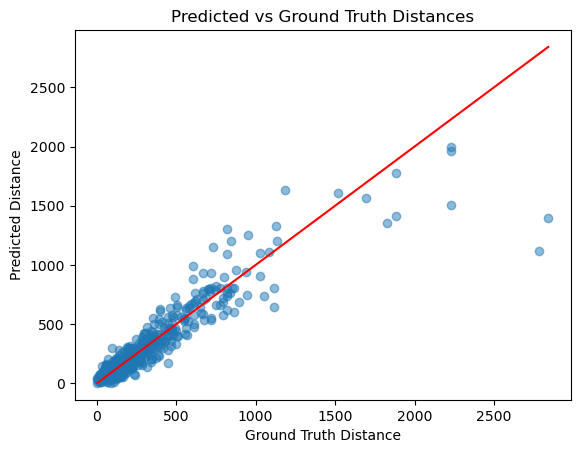

Evaluation 0.970703125 497 512 MAE: 1315.0724346076458


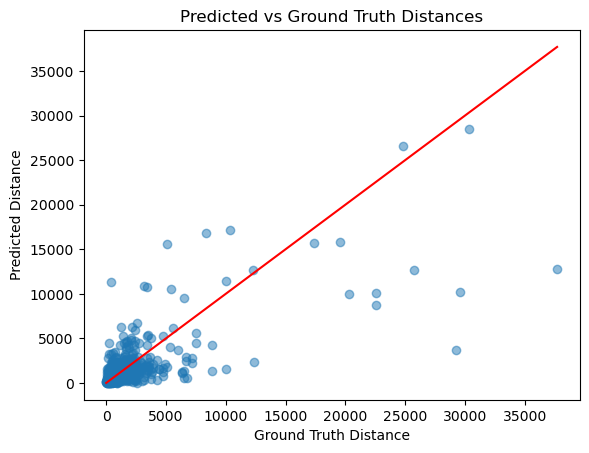

Evaluation 0.9765625 500 512 MAE: 609.83


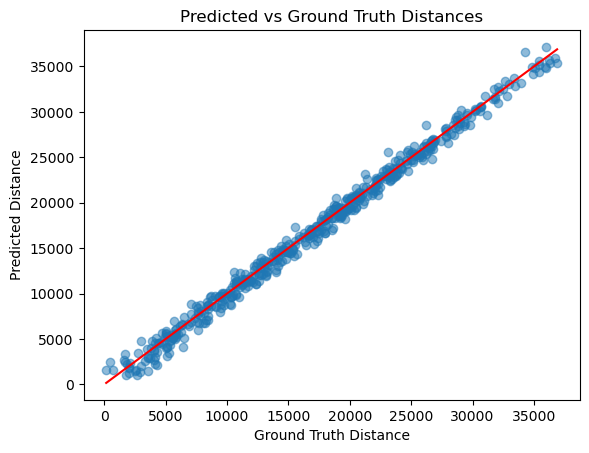

In [74]:
mae_mean = evaluate_model_val(tuned_model, tokenizer, dataloader_test_line, num_samples=512, printing=False, temperature=0.9, find_answer=find_answer_line,plot=True)
mae_mean = evaluate_model_val(tuned_model, tokenizer, dataloader_test_polygon, num_samples=512, printing=False, temperature=0.9, find_answer=find_answer_polygon,plot=True)
mae_mean = evaluate_model_val(tuned_model, tokenizer, dataloader_test_distance, num_samples=512, printing=False, temperature=0.9, find_answer=find_answer_distance,plot=True)